# Lab 15: Putting the Model Together

This lab assembles the reference Bayesian MMM used across the PyMC labs, on a national weekly aggregate of Sedge Shoes.
It accompanies Chapter 15 of the book Marketing Mix Modelling and follows the chapter's section on building in stages: first a model with the baseline, seasonality, the promotion treatment and the controls, then a check that this non-media structure can represent the business, and only then the media.
It is a deliberately simplified version of the book's model: national rather than regional, one Fourier pair for seasonality, a single launch indicator, and the adstock and Hill hyperparameters fixed at their true values (the generator's `ADSTOCK_ALPHA`, `HILL_SLOPE` and `HALF_MULT`) instead of being estimated.
Fixing them keeps the labs fast and focused, but it is a luxury you will not have on real data.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from mmm_book import RANDOM_SEED
from mmm_book.adstock import geometric_adstock
from mmm_book.plotting import mmm_style
from mmm_book.reference import (
    BETA_PRIOR_SHARE,
    build_controls,
    build_events,
    build_seasonality,
    build_treatments,
    national_aggregate,
    reference_model,
)
from mmm_book.saturation import hill_saturation
from mmm_book.sedge import ADSTOCK_ALPHA, CHANNELS, HALF_MULT, HILL_SLOPE, generate_sedge

mmm_style()

## From region-weeks to a national aggregate

Sedge is generated as a region-week panel (18 regions, 156 weeks), but the reference model in this and later labs works on a single national weekly series.
`national_aggregate` sums media and revenue across the 18 regions, giving one row per week, and averages the controls (price, promotion depth, distribution, stock, weather, the launch indicator and the category search index) so they stay on their natural scale.

In [2]:
df = generate_sedge()
nat = national_aggregate(df)
nat[["week", "revenue", "tv_grps", "meta_spend", "price", "promo_depth", "launch"]].head()

,week,revenue,tv_grps,meta_spend,price,promo_depth,launch
0,0,831734.242867,18.141137,33620.646406,95.157004,0.000000,0.0
1,1,866040.320301,16.407302,42928.007240,96.026189,0.000000,0.0
2,2,946662.294605,17.173466,45691.457691,93.905628,0.015422,0.0
3,3,946684.584773,17.701683,40660.150003,93.934775,0.007958,0.0
4,4,991953.126200,37.181342,32452.313601,95.582855,0.000000,0.0


## The pieces of equation 15.1

Chapter 15 writes expected revenue as a baseline, plus media, plus non-media treatments, plus controls.
The table maps each piece to the variable that carries it in this lab (Appendix B lists the book's symbols).

| Book | Here | What it is |
| --- | --- | --- |
| $\beta_0$ | `intercept` | the starting level of weekly revenue |
| $\nu$ | `trend` | the trend's slope per unit of the standardised week $\tilde{t}$ |
| $a_1$, $b_1$ | `season_a`, `season_b` | the heights of the annual sine and cosine waves, $S_t$ |
| $\omega_e$ | `omega_launch` | the effect of the launch event $E_{e,t}$ (1 in launch weeks) |
| $\delta_j$ | `delta_promo` | the effect of the promotion, a non-media treatment $Q_{j,t}$ |
| $\gamma_c$ | `gamma_log_price`, ... | the effect of each control $Z_{c,t}$ |
| $\beta_m$ | `beta_tv`, ... | each channel's scale |
| $\sigma$ | `sigma` | the standard deviation of the noise |

Revenue is in millions of pounds, so every coefficient is too.
The promotion and the controls are standardised (mean 0, standard deviation 1), so `delta_promo` and each `gamma` are millions of pounds per standard deviation of their input, rather than per unit as in the book.
The baseline's seasonality uses a cycle of $P$ = 52.18 weeks.

In [3]:
season = build_seasonality(nat)
events = build_events(nat)
treatments = build_treatments(nat)
controls = build_controls(nat)

y = nat["revenue"].to_numpy(dtype=float) / 1e6
week = nat["week"].to_numpy(dtype=float)
week_c = (week - week.mean()) / week.std()

print(f"controls: {', '.join(controls)}")
print(f"weekly revenue: mean {y.mean():.3f}m, standard deviation {y.std():.3f}m")

controls: log_price, distribution, stock, temperature, rainfall, category
weekly revenue: mean 0.922m, standard deviation 0.175m


## Correctly-specified media features

Each channel's driver is its spend, except for Television, which is in GRPs, and Paid Search, which uses generic search impressions because brand search spend follows demand rather than creating it.
The driver is adstocked with its own `ADSTOCK_ALPHA` ($\alpha_m$) and saturated with a Hill curve whose half-saturation point is `HALF_MULT` times the channel's average adstocked activity and whose shape is `HILL_SLOPE` (the book's $k_m$ and $s_m$).
These are the same transform hyperparameters the Sedge generator used to build the data.

One departure from the book matters for reading the betas.
In the book $\beta_m$ is the channel's weekly revenue at full saturation, because $f_m$ runs from 0 to 1 (Appendix B).
Here each saturated feature is divided by its own mean, so every feature averages one and `beta_ch` is the channel's average weekly contribution in millions of pounds instead.
The two differ by the channel's average Hill value.
The average puts all five betas on a comparable scale, so one prior scale works for all of them.

In [4]:
driver_col = {
    "tv": "tv_grps",
    "search": "search_generic_impr",
    "meta": "meta_spend",
    "youtube": "youtube_spend",
    "ooh": "ooh_spend",
}

feat = {}
for ch in CHANNELS:
    raw = nat[driver_col[ch]].to_numpy(dtype=float)
    ad = geometric_adstock(raw, alpha=ADSTOCK_ALPHA[ch], normalize=True)
    saturated = hill_saturation(ad, half=HALF_MULT[ch] * np.mean(ad), slope=HILL_SLOPE[ch])
    feat[ch] = saturated / saturated.mean()

## The model, in two stages

`build_model` writes the model out line by line.
With `include_media=False` it is the first stage: baseline, treatment and controls, with no media at all.
With `include_media=True` it adds one HalfNormal beta per channel, multiplied by that channel's feature, so every media effect is non-negative (Chapter 15's fifth modelling choice).

The priors are the ones Lab 17 arrives at with prior predictive checks, set on revenue's own scale.
Each channel's average weekly contribution has a HalfNormal prior whose scale is a tenth of mean weekly revenue (`BETA_PRIOR_SHARE`), and every other coefficient, and the noise, has a prior scale equal to the standard deviation of weekly revenue.
Lab 17 shows what goes wrong with looser, generic priors.

In [5]:
scale = y.std()


def build_model(include_media):
    with pm.Model() as model:
        intercept = pm.Normal("intercept", mu=y.mean(), sigma=scale)
        trend = pm.Normal("trend", 0, scale)
        season_a = pm.Normal("season_a", 0, scale)
        season_b = pm.Normal("season_b", 0, scale)
        omega = {name: pm.Normal(f"omega_{name}", 0, scale) for name in events}
        delta = {name: pm.Normal(f"delta_{name}", 0, scale) for name in treatments}
        gamma = {name: pm.Normal(f"gamma_{name}", 0, scale) for name in controls}
        mu = (
            intercept
            + trend * week_c
            + season_a * season["sin"]
            + season_b * season["cos"]
            + sum(omega[name] * events[name] for name in events)
            + sum(delta[name] * treatments[name] for name in treatments)
            + sum(gamma[name] * controls[name] for name in controls)
        )
        if include_media:
            beta_sigma = BETA_PRIOR_SHARE * y.mean()
            betas = {ch: pm.HalfNormal(f"beta_{ch}", sigma=beta_sigma) for ch in CHANNELS}
            mu = mu + sum(betas[ch] * feat[ch] for ch in CHANNELS)
        sigma = pm.HalfNormal("sigma", sigma=scale)
        pm.Normal("y", mu=mu, sigma=sigma, observed=y)
    return model


baseline_model = build_model(include_media=False)
print(baseline_model.str_repr())

         intercept ~ Normal(0.922, 0.175)
             trend ~ Normal(0, 0.175)
          season_a ~ Normal(0, 0.175)
          season_b ~ Normal(0, 0.175)
      omega_launch ~ Normal(0, 0.175)
       delta_promo ~ Normal(0, 0.175)
   gamma_log_price ~ Normal(0, 0.175)
gamma_distribution ~ Normal(0, 0.175)
       gamma_stock ~ Normal(0, 0.175)
 gamma_temperature ~ Normal(0, 0.175)
    gamma_rainfall ~ Normal(0, 0.175)
    gamma_category ~ Normal(0, 0.175)
             sigma ~ HalfNormal(0, 0.175)
                 y ~ Normal(f(gamma_category, delta_promo, gamma_rainfall, omega_launch, season_b, gamma_temperature, season_a, intercept, gamma_stock, trend, gamma_distribution, gamma_log_price), sigma)


## Sampling

Sampling uses the settings every lab uses: four chains of 1,000 draws after 1,000 warm-up steps, with a target acceptance rate of 0.95.
Every fit is checked before anything is read from it: no divergences, and every `r_hat` at or below 1.01.

In [6]:
SAMPLE_KWARGS = dict(
    draws=1000,
    tune=1000,
    chains=4,
    cores=1,
    target_accept=0.95,
    random_seed=RANDOM_SEED,
    progressbar=False,
)


def check(idata):
    n_divergent = int(idata.sample_stats["diverging"].sum())
    r_hat = float(az.summary(idata, kind="diagnostics")["r_hat"].max())
    print(f"divergent transitions: {n_divergent}, largest r_hat: {r_hat:.3f}")


with baseline_model:
    idata_baseline = pm.sample(**SAMPLE_KWARGS)
check(idata_baseline)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 6 seconds.


divergent transitions: 0, largest r_hat: 1.004


## Stage 1 check: can the non-media structure represent the business?

The first-stage model should track the broad shape of revenue, its level, seasonality, launches, promotions and price, and leave behind whatever it cannot explain.
Two things are worth looking at.
The fitted line against the observed series shows whether the structure is plausible at all.
The residuals' correlation with each channel's media feature shows what is left for media to explain: a channel whose feature lines up with the residuals is carrying revenue the first stage has nowhere to put.

residual standard deviation: 0.047m
  correlation of residuals with the tv feature: +0.48
  correlation of residuals with the search feature: -0.02
  correlation of residuals with the meta feature: +0.33
  correlation of residuals with the youtube feature: +0.34
  correlation of residuals with the ooh feature: +0.09


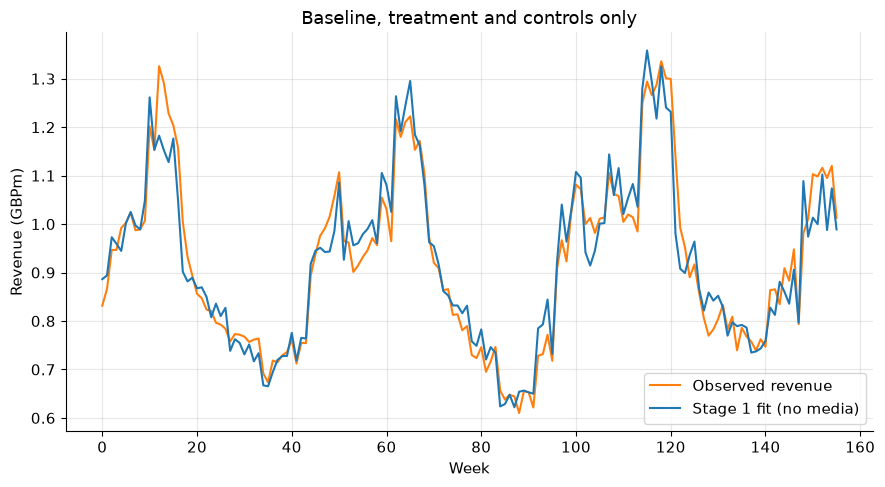

In [7]:
def fitted_mean(idata, names):
    post = idata.posterior
    mean = {name: float(post[name].mean()) for name in names}
    fit = (
        mean["intercept"]
        + mean["trend"] * week_c
        + mean["season_a"] * season["sin"]
        + mean["season_b"] * season["cos"]
        + sum(mean[f"omega_{n}"] * events[n] for n in events)
        + sum(mean[f"delta_{n}"] * treatments[n] for n in treatments)
        + sum(mean[f"gamma_{n}"] * controls[n] for n in controls)
    )
    return fit + sum(mean.get(f"beta_{ch}", 0.0) * feat[ch] for ch in CHANNELS)


baseline_names = list(idata_baseline.posterior.data_vars)
baseline_fit = fitted_mean(idata_baseline, baseline_names)
residual = y - baseline_fit

fig, ax = plt.subplots()
ax.plot(week, y, color="C1", label="Observed revenue")
ax.plot(week, baseline_fit, color="C0", label="Stage 1 fit (no media)")
ax.set_xlabel("Week")
ax.set_ylabel("Revenue (GBPm)")
ax.set_title("Baseline, treatment and controls only")
ax.legend()
fig.tight_layout()

print(f"residual standard deviation: {residual.std():.3f}m")
for ch in CHANNELS:
    print(
        f"  correlation of residuals with the {ch} feature: "
        f"{np.corrcoef(residual, feat[ch])[0, 1]:+.2f}"
    )

The first stage follows the level, the seasonal swing and the launch weeks, so the non-media structure is a plausible description of the business.
What it leaves behind lines up with the media: the residuals correlate with Television's feature (+0.48), whose flights are revenue the first stage cannot place, and with YouTube's (+0.34), Meta's (+0.33) and, weakly, OOH's (about +0.1).
Search's feature does not line up (-0.02): its spend follows category demand, which the category control already carries, a first hint of why Search is hard to pin down.
That is the signal to add the media, which is the second stage.

In [8]:
model = build_model(include_media=True)

# The second stage is exactly the reference model the later labs import.
assert [rv.name for rv in model.free_RVs] == [rv.name for rv in reference_model(nat).free_RVs]

with model:
    idata = pm.sample(**SAMPLE_KWARGS)
check(idata)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


divergent transitions: 0, largest r_hat: 1.004


In [9]:
summary = az.summary(idata, var_names=[f"beta_{ch}" for ch in CHANNELS], ci_prob=0.9)
print(summary)

full_fit = fitted_mean(idata, list(idata.posterior.data_vars))
print(f"\nresidual standard deviation, stage 1: {residual.std():.3f}m")
print(f"residual standard deviation, stage 2: {(y - full_fit).std():.3f}m")

                mean      sd eti90_lb eti90_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
beta_tv       0.0644  0.0035    0.059     0.07     4323     3003  1.00   5.3e-05  5.4e-05
beta_search    0.084   0.039     0.02     0.15     2135     1547  1.00   0.00081  0.00061
beta_meta     0.0887  0.0238    0.046     0.13     3435     2226  1.00   0.00041  0.00037
beta_youtube  0.0157  0.0114   0.0014    0.038     2561     1956  1.00   0.00021  0.00018
beta_ooh       0.026   0.017   0.0025    0.058     2571     1691  1.00   0.00028  0.00023

residual standard deviation, stage 1: 0.047m
residual standard deviation, stage 2: 0.022m


## Takeaway

The model was built the way Chapter 15 recommends: a baseline, the promotion treatment and the controls first, checked against the data, and media added only once the first stage had shown what it could not explain.
Adding the media takes the typical miss from about 47,000 pounds a week to about 22,000, and every channel gets a beta with a 90 per cent interval.
The model is still a skeleton: national, with fixed transforms and one non-negative beta per channel.
Lab 17 shows why its priors are set the way they are, and Lab 19 adds the next stage the book describes, a hierarchy across regions, together with a time-varying effect.